In [26]:
import pandas as pd

df = pd.read_csv("./../Cell_Painting_Median_Features_Median_doses.csv")


In [27]:
from rdkit import Chem
import pandas as pd
from pandarallel import pandarallel
pandarallel.initialize(progress_bar = True)
# Assume your DataFrame is called `df` and contains a column named 'InChICode_standardised'

def inchi_to_inchikey(inchi):
    try:
        mol = Chem.MolFromInchi(inchi)
        if mol:
            return Chem.InchiToInchiKey(inchi)
        else:
            return None
    except:
        return None

# Apply conversion
df["InChIKey"] = df["InChICode_standardised"].parallel_apply(inchi_to_inchikey)
df

INFO: Pandarallel will run on 40 workers.
INFO: Pandarallel will use Memory file system to transfer data between the main process and workers.


[16:41:36] WARNING: not removing hydrogen atom without neighbors
[16:41:36] WARNING: not removing hydrogen atom without neighbors


,InChICode_standardised,index,Metadata_mmoles_per_liter,Cells_AreaShape_Area,Cells_AreaShape_Center_X,Cells_AreaShape_Center_Y,Cells_AreaShape_Compactness,Cells_AreaShape_Eccentricity,Cells_AreaShape_EulerNumber,Cells_AreaShape_Extent,...,Nuclei_Texture_Variance_ER_10_0,Nuclei_Texture_Variance_ER_3_0,Nuclei_Texture_Variance_ER_5_0,Nuclei_Texture_Variance_Mito_10_0,Nuclei_Texture_Variance_Mito_3_0,Nuclei_Texture_Variance_Mito_5_0,Nuclei_Texture_Variance_RNA_10_0,Nuclei_Texture_Variance_RNA_3_0,Nuclei_Texture_Variance_RNA_5_0,InChIKey
0,InChI=1S/C12H15N3O2S/c1-7(2)18-8-4-5-9-10(6-8)...,960.0,5.000000,1728.953125,-1.375000,-25.445312,-0.067918,-0.062396,0.0,0.026443,...,0.314918,0.222859,0.280258,0.192997,0.144917,0.168085,-0.332871,-0.314733,-0.313477,SXJIZQPZESTWLD-UHFFFAOYSA-N
1,InChI=1S/C12H18N4O3/c1-7(2)5-16-10-9(11(17)15(...,1036.0,5.000000,-272.074219,11.464844,-1.628906,-0.001808,-0.006674,0.0,-0.001405,...,0.023860,-0.016903,-0.017773,-0.028029,-0.038308,-0.041455,-0.070389,-0.067789,-0.071673,NBLBCGUCPBXKOV-UHFFFAOYSA-N
2,InChI=1S/C16H29N5O3/c1-12-9-20(13(2)10-22)16(2...,4942.5,4.973595,101.958984,15.673828,-2.314453,0.010687,0.013397,0.0,-0.003746,...,-0.014119,0.035703,0.016875,-0.039304,-0.070028,-0.062892,-0.015647,-0.038908,-0.026464,FOLOUAULJSJVDY-GZBFAFLISA-N
3,InChI=1S/C16H29N5O3/c1-12-9-20(13(2)10-22)16(2...,4944.5,4.912934,-109.708984,-10.203125,1.718750,0.025025,0.014627,0.0,-0.007164,...,0.046218,0.031759,0.037029,-0.051411,-0.083061,-0.071562,-0.024598,-0.052021,-0.043327,FOLOUAULJSJVDY-IPYPFGDCSA-N
4,InChI=1S/C16H29N5O3/c1-12-9-20(13(2)10-22)16(2...,4949.5,5.012874,-234.222656,8.873047,3.308594,0.010192,0.005251,0.0,-0.003173,...,-0.072889,-0.030955,-0.037623,-0.009460,0.004604,-0.010465,-0.031869,-0.025910,-0.014907,FOLOUAULJSJVDY-NFAWXSAZSA-N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30399,InChI=1S/C9H9N5OS2/c10-12-8(16)11-6-3-1-2-5(4-...,30588.0,5.000000,-226.027344,-18.847656,-0.511719,-0.005827,0.004864,0.0,0.003590,...,-0.114357,-0.123664,-0.127474,-0.069665,-0.056972,-0.044186,-0.019668,-0.091541,-0.062515,LHXWPDUWZAYBJV-UHFFFAOYSA-N
30400,InChI=1S/C9H9NO/c11-6-7-5-10-9-4-2-1-3-8(7)9/h...,30589.0,5.000000,254.769531,18.886719,-3.589844,0.027814,0.016943,0.0,-0.000781,...,-0.079942,-0.018155,-0.017759,-0.118369,-0.046322,-0.023926,0.033498,0.051214,0.016060,IVYPNXXAYMYVSP-UHFFFAOYSA-N
30401,InChI=1S/C9H9NO2/c10-8-3-1-2-7(6-8)4-5-9(11)12...,30590.0,5.000000,238.574219,-0.699219,6.625000,0.005228,0.008800,0.0,0.002336,...,-0.107812,-0.107077,-0.138399,0.168811,0.216703,0.195851,-0.063656,-0.042877,-0.071681,JNXMJSYJCFTLJB-SNAWJCMRSA-N
30402,InChI=1S/C9H9NO3S/c1-6(11)5-14-8-3-2-7(4-10-8)...,30591.0,5.000000,-238.945312,5.476562,0.089844,0.018032,0.012711,0.0,-0.004635,...,-0.070647,-0.095379,-0.102060,0.023423,0.049321,0.041996,0.023470,0.058959,0.065934,LRBIKSYRCFHKBN-UHFFFAOYSA-N


In [28]:
promicuous_compounds = pd.read_csv("data/promicuous_compounds_with_assay_data.csv")

promicuous_compounds

,n_active_hits,BROAD_ID,InChIKey
0,2,BRD-A01717918-001-05-5,JEFNGIWYLXETLU-UHFFFAOYSA-N
1,1,BRD-A02214146-001-06-4,TYLHRPBDFWODNS-UHFFFAOYSA-N
2,8,BRD-A02481876-001-08-1,HKGJEZIGDHFJFL-UHFFFAOYSA-N
3,3,BRD-A02927672-001-06-3,TXQUPVHAFRNVNR-UHFFFAOYSA-N
4,12,BRD-A03764094-001-09-3,QCGHTRAZOATGMB-UHFFFAOYSA-N
...,...,...,...
24710,0,BRD-K33086245-001-05-9,ZZSBFYCJHLWUNQ-UHFFFAOYSA-N
24711,0,BRD-K78010432-001-04-1,ZZUFCTLCJUWOSV-UHFFFAOYSA-N
24712,2,BRD-K96799727-001-01-7,ZZUZYEMRHCMVTB-UHFFFAOYSA-N
24713,4,BRD-K47278471-003-04-0,ZZVUWRFHKOJYTH-UHFFFAOYSA-N


In [29]:
df = df[["InChIKey",  "Cells_Number_Object_Number"]]
df

,InChIKey,Cells_Number_Object_Number
0,SXJIZQPZESTWLD-UHFFFAOYSA-N,-26.265625
1,NBLBCGUCPBXKOV-UHFFFAOYSA-N,4.812500
2,FOLOUAULJSJVDY-GZBFAFLISA-N,-2.435547
3,FOLOUAULJSJVDY-IPYPFGDCSA-N,0.964844
4,FOLOUAULJSJVDY-NFAWXSAZSA-N,2.212891
...,...,...
30399,LHXWPDUWZAYBJV-UHFFFAOYSA-N,2.714844
30400,IVYPNXXAYMYVSP-UHFFFAOYSA-N,-10.828125
30401,JNXMJSYJCFTLJB-SNAWJCMRSA-N,-0.078125
30402,LRBIKSYRCFHKBN-UHFFFAOYSA-N,-0.078125


In [30]:
promicuous_df = pd.merge(promicuous_compounds, df,
                         left_on="InChIKey",
                        right_on="InChIKey")
promicuous_df

,n_active_hits,BROAD_ID,InChIKey,Cells_Number_Object_Number
0,2,BRD-A01717918-001-05-5,JEFNGIWYLXETLU-UHFFFAOYSA-N,1.328125
1,1,BRD-A02214146-001-06-4,TYLHRPBDFWODNS-UHFFFAOYSA-N,2.503906
2,8,BRD-A02481876-001-08-1,HKGJEZIGDHFJFL-UHFFFAOYSA-N,-8.250000
3,3,BRD-A02927672-001-06-3,TXQUPVHAFRNVNR-UHFFFAOYSA-N,-7.804688
4,12,BRD-A03764094-001-09-3,QCGHTRAZOATGMB-UHFFFAOYSA-N,-10.960938
...,...,...,...,...
24710,0,BRD-K33086245-001-05-9,ZZSBFYCJHLWUNQ-UHFFFAOYSA-N,1.195312
24711,0,BRD-K78010432-001-04-1,ZZUFCTLCJUWOSV-UHFFFAOYSA-N,-10.746094
24712,2,BRD-K96799727-001-01-7,ZZUZYEMRHCMVTB-UHFFFAOYSA-N,-16.304688
24713,4,BRD-K47278471-003-04-0,ZZVUWRFHKOJYTH-UHFFFAOYSA-N,-1.664062


In [31]:
promicuous_df.InChIKey.nunique()

24606

In [32]:
promicuous_df.n_active_hits.value_counts()

0     11040
1      6472
2      3039
3      1571
4       891
5       553
6       324
7       218
8       168
9       107
10       86
11       47
12       35
14       26
13       18
15       18
16       14
17       10
22        7
18        6
32        4
27        4
19        4
24        3
25        3
29        3
28        3
77        3
21        3
33        2
26        2
41        2
30        2
70        2
39        2
76        2
43        1
37        1
23        1
57        1
52        1
75        1
40        1
20        1
80        1
38        1
65        1
61        1
31        1
48        1
45        1
60        1
86        1
36        1
35        1
47        1
68        1
Name: n_active_hits, dtype: int64

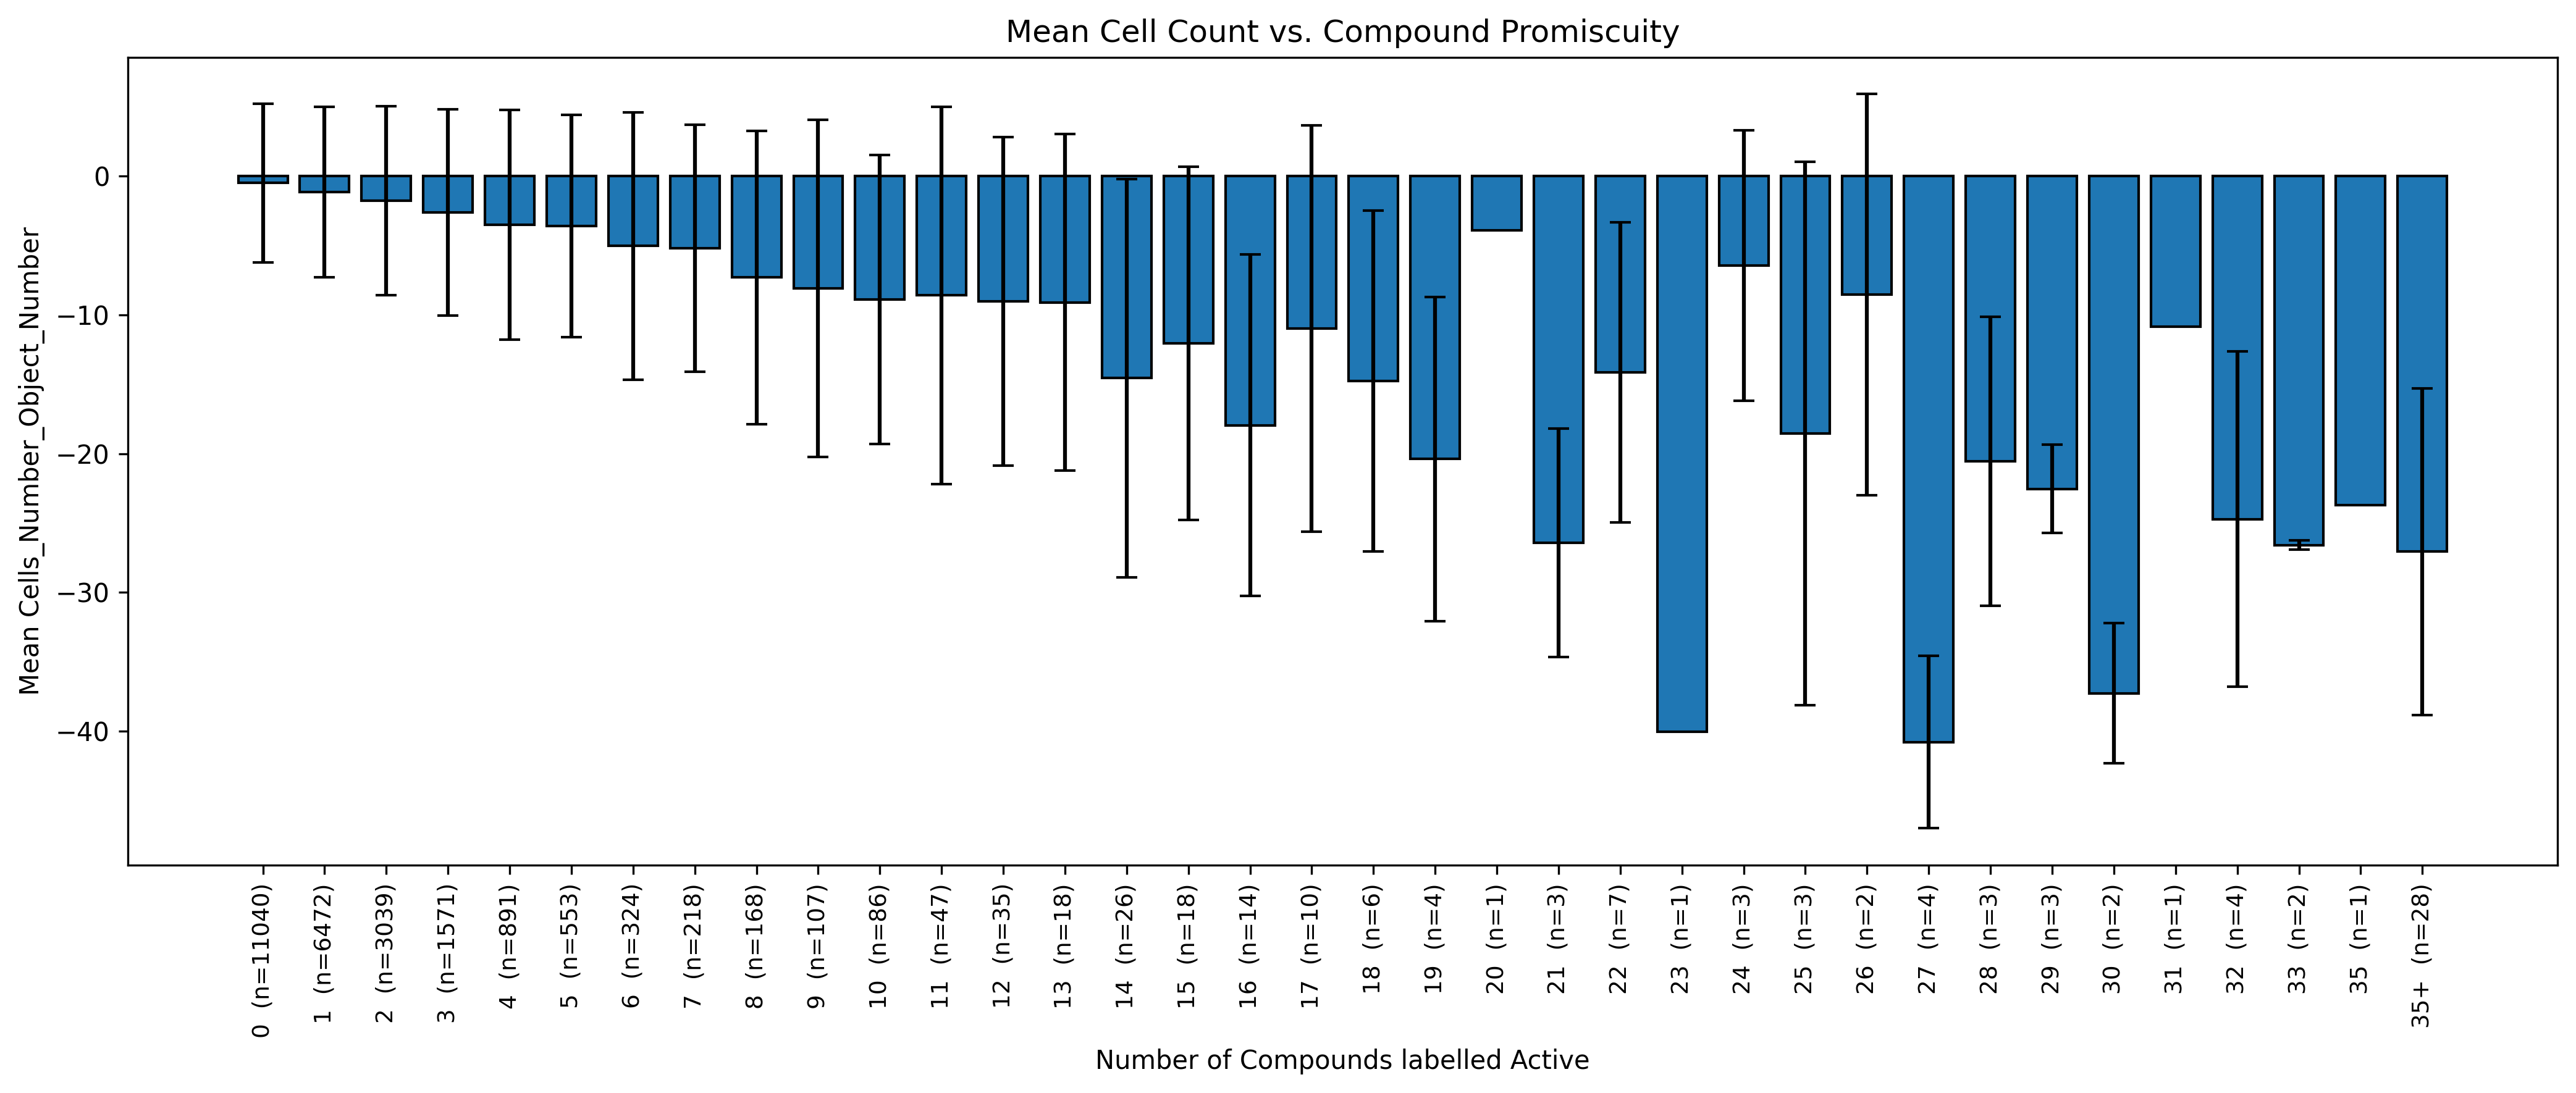

In [33]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# -------- Data prep --------
feature = "Cells_Number_Object_Number"

# Cap high n_active_hits to 35+
promicuous_df["n_active_hits_binned"] = promicuous_df["n_active_hits"].apply(
    lambda x: x if x <= 35 else 36  # we'll label 36 as '35+'
)

# Group by binned hits
group_stats = (
    promicuous_df
    .groupby("n_active_hits_binned")[feature]
    .agg(["mean", "std", "count"])
    .reset_index()
)

# Create label column
group_stats["label"] = group_stats["n_active_hits_binned"].apply(
    lambda x: f"{x}" if x <= 35 else "35+"
) + group_stats["count"].apply(lambda n: f"  (n={n})")

# -------- Plot --------
plt.figure(figsize=(14, 6), dpi=300)

# Bar plot with error bars
plt.bar(
    group_stats["label"],
    group_stats["mean"],
    yerr=group_stats["std"],
    capsize=4,
    edgecolor="black"
)

# Final formatting
plt.xticks(rotation=90, fontsize=9)
plt.ylabel(f"Mean {feature}")
plt.xlabel("Number of Compounds labelled Active")
plt.title("Mean Cell Count vs. Compound Promiscuity")
plt.tight_layout()
plt.show()
